# Socioeconomic data, emissions and accounting balances

## Purpose and scope

This deep dive examines the coverage and distributions of territorial emissions, GDP and population, then shows how these variables enter the account balances and ratios. GCB emissions refer to 2024. GDP and population are selected separately for each study unit using the latest available value in the order 2024, 2023, then 2022.

The notebook makes sample coverage visible before presenting comparisons. Its scatter plots are descriptive and do not establish that carbon wealth causes emissions or economic performance.

## Load the prepared socioeconomic and emissions table

The canonical table contains 2024 territorial fossil and industrial emissions and the selected GDP and population values. The latter follow the per-variable 2024 → 2023 → 2022 fallback. The output field names retain their 2024 reference label; the selection rule is documented here and in the pipeline guide.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start):
    for candidate in (start, *start.parents):
        if (candidate / "code" / "notebooks").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the repository from the notebook working directory.")

ROOT = find_repo_root(Path.cwd().resolve())
while ROOT != ROOT.parent and not (ROOT / 'pyproject.toml').is_file():
    ROOT = ROOT.parent
if not (ROOT / 'pyproject.toml').is_file():
    raise FileNotFoundError('Run this notebook from within the repository.')

DATA = ROOT / 'data' / 'derived'
RESULTS = ROOT / 'results'
TABLES = RESULTS / 'tables' / 'manuscript'
VALIDATION = ROOT / 'data' / 'outputs' / 'validation'
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
print(f'Repository: {ROOT}')

Repository: /workspace/ncw


## 2. Establish which observations can be compared

Coverage counts are calculated over the GCW study-unit set. The separate counts show where emissions, GDP and population are available individually and jointly. The complete-case sample used in a comparison can therefore be smaller than the account universe.

In [2]:
accounts = pd.read_csv(TABLES / 'Supplementary_country_level_accounts_2024.csv')
gcw_mask = accounts['has_gcw'].fillna(False).astype(bool)
coverage_fields = {
    'CO2 emissions 2024 (tCO2/year)': 'co2_emissions_tco2_2024',
    'Population 2024': 'population_2024',
    'GDP 2024 (2015 US$)': 'gdp_2015usd_2024',
}
coverage = []
for label, col in coverage_fields.items():
    coverage.append({'variable': label, 'available_units': int(accounts.loc[gcw_mask, col].notna().sum()), 'gcw_units': int(gcw_mask.sum()), 'missing_units': int(gcw_mask.sum() - accounts.loc[gcw_mask, col].notna().sum())})
coverage.append({'variable':'All three variables', 'available_units':int(accounts.loc[gcw_mask, list(coverage_fields.values())].notna().all(axis=1).sum()), 'gcw_units':int(gcw_mask.sum()), 'missing_units':int(gcw_mask.sum() - accounts.loc[gcw_mask, list(coverage_fields.values())].notna().all(axis=1).sum())})
display(pd.DataFrame(coverage))

,variable,available_units,gcw_units,missing_units
0,CO2 emissions 2024 (tCO2/year),210,236,26
1,Population 2024,213,236,23
2,GDP 2024 (2015 US$),204,236,32
3,All three variables,195,236,41


## 3. Inspect economic scale and the GCW-to-GDP ratio

The summary tables show variable ranges and group coverage. The plot below compares selected GDP per capita with GCW as a share of GDP among units with both values. Its purpose is to reveal scale and dispersion; it is not a fitted or causal model.

In [3]:
selected = accounts.loc[gcw_mask, ['UNIT_CODE', 'name', 'groups', 'region', *coverage_fields.values()]].copy()
for col in coverage_fields.values():
    selected[col] = pd.to_numeric(selected[col], errors='coerce')
display(selected[list(coverage_fields.values())].describe(percentiles=[.05, .25, .5, .75, .95]).T)
selected['groups'] = selected['groups'].fillna('Unclassified')
selected['region'] = selected['region'].fillna('Unclassified')
display(selected.groupby(['groups', 'region'], dropna=False).agg(units=('UNIT_CODE','size'), emissions_covered=('co2_emissions_tco2_2024','count'), population_covered=('population_2024','count'), gdp_covered=('gdp_2015usd_2024','count')).reset_index())

,count,mean,std,min,5%,25%,50%,75%,95%,max
co2_emissions_tco2_2024,210.0,1.766730e+08,9.481467e+08,7.626998e+03,1.446167e+05,1.666950e+06,1.129808e+07,5.534368e+07,5.242026e+08,1.228904e+10
population_2024,213.0,3.806343e+07,1.440912e+08,9.646000e+03,4.390680e+04,8.666280e+05,6.916140e+06,2.719429e+07,1.267296e+08,1.450936e+09
gdp_2015usd_2024,204.0,4.687043e+11,2.123712e+12,4.227733e+07,9.054033e+08,7.422323e+09,2.909312e+10,2.200654e+11,1.831249e+12,2.273147e+13


,groups,region,units,emissions_covered,population_covered,gdp_covered
0,Developed economies,Africa,1,0,0,0
1,Developed economies,Americas,4,4,3,3
2,Developed economies,Asia,4,4,4,4
3,Developed economies,Europe,50,42,46,44
4,Developed economies,Oceania,3,2,2,2
5,Developing economies,Africa,21,19,18,18
6,Developing economies,Americas,19,17,17,17
7,Developing economies,Asia,34,34,34,33
8,Developing economies,Caribbean,3,1,1,0
9,Developing economies,Oceania,3,1,0,0


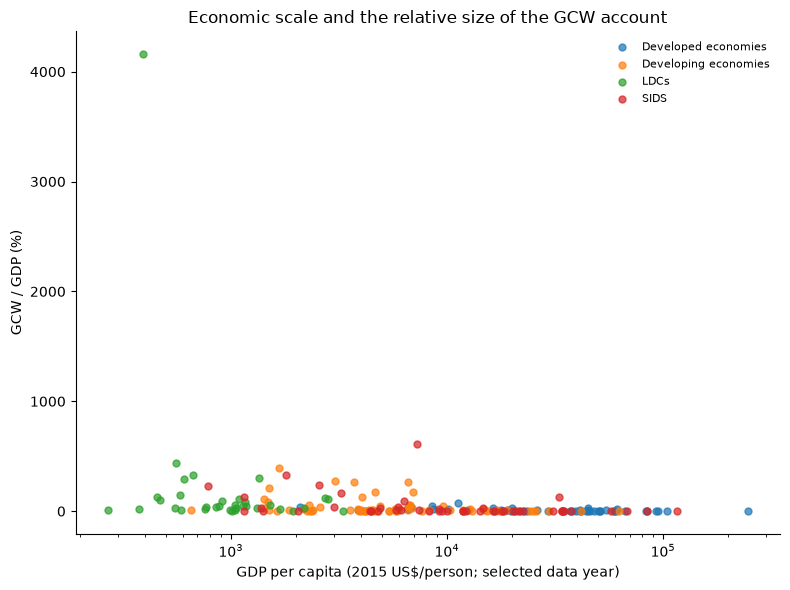

In [4]:
plot_data = accounts.loc[gcw_mask, ["UNIT_CODE", "name", "groups", "gdp_per_capita_2024", "gcw_gdp_2024_pct"]].copy()
plot_data["gdp_pc"] = pd.to_numeric(plot_data["gdp_per_capita_2024"], errors="coerce")
plot_data["gcw_gdp_pct"] = pd.to_numeric(plot_data["gcw_gdp_2024_pct"], errors="coerce")
plot_data = plot_data.loc[plot_data["gdp_pc"].gt(0) & plot_data["gcw_gdp_pct"].notna()]
plot_data["group_plot"] = plot_data["groups"].fillna("Unclassified")

fig, ax = plt.subplots(figsize=(8, 6))
for group, frame in plot_data.groupby("group_plot", dropna=False):
    ax.scatter(frame["gdp_pc"], frame["gcw_gdp_pct"], s=25, alpha=0.72, label=group)
ax.set_xscale("log")
ax.set_xlabel("GDP per capita (2015 US$/person; selected data year)")
ax.set_ylabel("GCW / GDP (%)")
ax.set_title("Economic scale and the relative size of the GCW account")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

## 4. Read emissions changes and accounting balances

The emissions-change table compares releases of the GCB series. The balance tables place annual carbon-account flows beside 2024 territorial emissions. These quantities have different scopes and reservoirs: the balance is a descriptive comparison, not a complete national greenhouse-gas inventory.

In [5]:
emissions_change = pd.read_csv(VALIDATION / 'gcb2025_emissions_change_2023_2024_by_unit.csv')
balance_units = pd.read_csv(TABLES / 'Supplementary_accounting_balances_2024_by_unit.csv')
balance_groups = pd.read_csv(TABLES / 'Supplementary_accounting_balance_transitions.csv')
print('Emissions-change output columns:', emissions_change.columns.tolist())
display(emissions_change.head(15))
display(balance_groups)
display(balance_units.head(15))

Emissions-change output columns: ['iso3', 'name', 'gcb_name', 'co2_emissions_tco2_2023_gcb2025', 'co2_emissions_tco2_2024', 'absolute_change_tco2', 'pct_change']


,iso3,name,gcb_name,co2_emissions_tco2_2023_gcb2025,co2_emissions_tco2_2024,absolute_change_tco2,pct_change
0,RUS,Russian Federation,Russia,1.733135e+09,1.780524e+09,4.738979e+07,2.734340
1,BRA,Brazil,Brazil,4.839919e+08,4.830116e+08,-9.803780e+05,-0.202561
2,USA,United States of America,USA,4.918407e+09,4.904120e+09,-1.428703e+07,-0.290481
3,CHN,"China (incl. Taiwan, Hong Kong SAR and Macao SAR)",China,1.217201e+10,1.228904e+10,1.170277e+08,0.961450
4,CAN,Canada,Canada,5.454785e+08,5.333401e+08,-1.213841e+07,-2.225278
5,AUS,Australia,Australia,3.843161e+08,3.867324e+08,2.416327e+06,0.628734
6,COD,Democratic Republic of the Congo,Democratic Republic of the Congo,5.881086e+06,5.904451e+06,2.336452e+04,0.397282
7,IDN,Indonesia,Indonesia,7.623575e+08,8.122202e+08,4.986269e+07,6.540592
8,IND,India,India,3.062756e+09,3.193478e+09,1.307216e+08,4.268103
9,MEX,Mexico,Mexico,4.582539e+08,4.609876e+08,2.733774e+06,0.596563


,before_gcw_balance_positive,after_ncw_balance_positive,units,common_sample_n
0,True,True,79,208
1,True,False,0,208
2,False,True,35,208
3,False,False,94,208


,UNIT_CODE,ISO3,name,region,iso3,co2_emissions_tco2_2024,gcw_additions_tco2_yr,gcw_accounting_balance_mean_tco2_yr,gcw_accounting_balance_p05_tco2_yr,gcw_accounting_balance_p50_tco2_yr,gcw_accounting_balance_p95_tco2_yr,ncw_accounting_balance_mean_tco2_yr,ncw_accounting_balance_p05_tco2_yr,ncw_accounting_balance_p50_tco2_yr,ncw_accounting_balance_p95_tco2_yr,fra_region,groups_x,gcw_additions_to_emissions_ratio,has_gcw,has_bcw,groups_y,gcw_usd2015_yr_mean,bcw_usd2015_yr_mean
0,ABW,ABW,Aruba,Caribbean,ABW,9.206439e+05,1.678803e+03,-9.189651e+05,-9.189651e+05,-9.189651e+05,-9.189651e+05,-8.916527e+05,-9.123483e+05,-8.980664e+05,-8.497417e+05,North and Central America,SIDS,0.001824,True,True,SIDS,9.394126e+05,1.529748e+07
1,AFG,AFG,Afghanistan,Asia,AFG,1.082600e+07,6.086587e+06,-4.739411e+06,-4.739411e+06,-4.739411e+06,-4.739411e+06,-4.739411e+06,-4.739411e+06,-4.739411e+06,-4.739411e+06,Asia,LDCs,0.562219,True,False,LDCs,3.405889e+09,NaN
2,AGO,AGO,Angola,Africa,AGO,2.233358e+07,2.167448e+08,1.944113e+08,1.944113e+08,1.944113e+08,1.944113e+08,2.390822e+08,2.386116e+08,2.389574e+08,2.399642e+08,Africa,LDCs,9.704885,True,True,LDCs,1.212845e+11,2.499639e+10
3,AIA,AIA,Anguilla,Caribbean,AIA,1.480854e+05,1.884371e+04,-1.292417e+05,-1.292417e+05,-1.292417e+05,-1.292417e+05,-1.171467e+05,-1.264957e+05,-1.200775e+05,-9.813288e+04,North and Central America,SIDS,0.127249,True,True,SIDS,1.054443e+07,6.775323e+06
4,ALB,ALB,Albania,Europe,ALB,4.444448e+06,4.811388e+06,3.669399e+05,3.669399e+05,3.669399e+05,3.669399e+05,7.165745e+05,6.891647e+05,7.079518e+05,7.723473e+05,Europe,Developed economies,1.082561,True,True,Developed economies,2.692322e+09,1.956678e+08
5,AND,AND,Andorra,Europe,AND,4.246630e+05,9.553813e+04,-3.291248e+05,-3.291248e+05,-3.291248e+05,-3.291248e+05,-3.291248e+05,-3.291248e+05,-3.291248e+05,-3.291248e+05,Europe,Developed economies,0.224974,True,True,Developed economies,5.346055e+07,0.000000e+00
6,ARE,ARE,United Arab Emirates,Asia,ARE,2.219881e+08,1.112053e+06,-2.208760e+08,-2.208760e+08,-2.208760e+08,-2.208760e+08,-2.199612e+08,-2.206147e+08,-2.201562e+08,-2.186555e+08,Asia,Developing economies,0.005010,True,True,Developing economies,6.222745e+08,5.122423e+08
7,ARG,ARG,Argentina,Americas,ARG,1.710593e+08,1.804308e+08,9.371481e+06,9.371481e+06,9.371481e+06,9.371481e+06,4.846805e+07,4.846805e+07,4.846805e+07,4.846805e+07,South America,Developing economies,1.054785,True,True,Developing economies,1.009642e+11,2.187738e+10
8,ARM,ARM,Armenia,Asia,ARM,7.430715e+06,1.707546e+06,-5.723170e+06,-5.723170e+06,-5.723170e+06,-5.723170e+06,-5.723170e+06,-5.723170e+06,-5.723170e+06,-5.723170e+06,Asia,Developing economies,0.229796,True,True,Developing economies,9.554964e+08,0.000000e+00
9,ATG,ATG,Antigua and Barbuda,Caribbean,ATG,6.651404e+05,2.668954e+04,-6.384509e+05,-6.384509e+05,-6.384509e+05,-6.384509e+05,3.630834e+05,2.067325e+05,3.147135e+05,6.791823e+05,North and Central America,SIDS,0.040126,True,True,SIDS,1.493474e+07,5.605367e+08
